In [4]:
import pandas as pd

df = pd.read_csv('/content/phishing_url_dataset.csv')

df.head()

,url_length,valid_url,at_symbol,sensitive_words_count,path_length,isHttps,nb_dots,nb_hyphens,nb_and,nb_or,nb_www,nb_com,nb_underscore,target
0,42,0,0,0,20,0,2,0,0,0,1,1,0,0
1,73,0,0,0,52,0,5,0,0,0,0,1,0,0
2,73,0,0,0,52,0,5,0,0,0,0,1,0,0
3,73,0,0,0,52,0,5,1,0,1,0,1,0,0
4,73,0,0,0,52,0,5,0,0,0,0,1,0,0


In [5]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Number of rows and columns: (2488, 14)

Column names:
['url_length', 'valid_url', 'at_symbol', 'sensitive_words_count', 'path_length', 'isHttps', 'nb_dots', 'nb_hyphens', 'nb_and', 'nb_or', 'nb_www', 'nb_com', 'nb_underscore', 'target']

Data types:
url_length               int64
valid_url                int64
at_symbol                int64
sensitive_words_count    int64
path_length              int64
isHttps                  int64
nb_dots                  int64
nb_hyphens               int64
nb_and                   int64
nb_or                    int64
nb_www                   int64
nb_com                   int64
nb_underscore            int64
target                   int64
dtype: object


In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
url_length               0
valid_url                0
at_symbol                0
sensitive_words_count    0
path_length              0
isHttps                  0
nb_dots                  0
nb_hyphens               0
nb_and                   0
nb_or                    0
nb_www                   0
nb_com                   0
nb_underscore            0
target                   0
dtype: int64


In [6]:
print("\nTotal missing values:", df.isnull().sum().sum())


Total missing values: 0


In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1134


In [8]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (1354, 14)


In [9]:
df.describe()

,url_length,valid_url,at_symbol,sensitive_words_count,path_length,isHttps,nb_dots,nb_hyphens,nb_and,nb_or,nb_www,nb_com,nb_underscore,target
count,1354.000000,1354.000000,1354.000000,1354.000000,1354.000000,1354.000000,1354.000000,1354.000000,1354.000000,1354.000000,1354.000000,1354.000000,1354.000000,1354.000000
mean,51.794682,0.119645,0.015510,0.150665,15.368538,0.277696,3.953471,0.775480,0.025111,0.262186,0.296160,0.675775,0.154357,0.331610
std,20.093369,0.324666,0.331489,0.408035,19.320939,0.448028,2.165043,1.402075,0.161172,0.505640,0.477305,0.564184,0.575901,0.470966
min,13.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,55.000000,0.000000,0.000000,0.000000,2.000000,0.000000,4.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
75%,73.000000,0.000000,0.000000,0.000000,33.000000,1.000000,5.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000
max,96.000000,1.000000,9.000000,3.000000,85.000000,1.000000,13.000000,10.000000,2.000000,3.000000,2.000000,3.000000,7.000000,1.000000


In [10]:
print(df['target'].value_counts())

target
0    905
1    449
Name: count, dtype: int64


In [11]:
print(df['target'].value_counts(normalize=True) * 100)

target
0    66.838996
1    33.161004
Name: proportion, dtype: float64


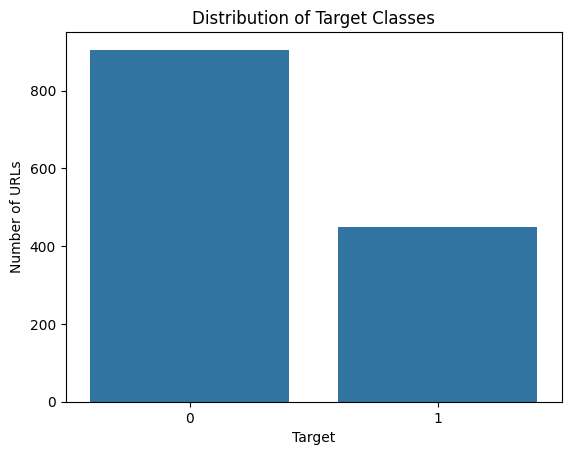

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='target', data=df)

plt.title('Distribution of Target Classes')
plt.xlabel('Target')
plt.ylabel('Number of URLs')

plt.show()

In [13]:
print(df['target'].unique())

[0 1]


In [14]:
print(df.groupby('target').mean(numeric_only=True))

        url_length  valid_url  at_symbol  sensitive_words_count  path_length  \
target                                                                         
0        49.567956   0.014365   0.022099               0.107182    16.317127   
1        56.282851   0.331849   0.002227               0.238307    13.456570   

         isHttps   nb_dots  nb_hyphens    nb_and     nb_or    nb_www  \
target                                                                 
0       0.246409  3.744751    0.644199  0.032044  0.261878  0.375691   
1       0.340757  4.374165    1.040089  0.011136  0.262806  0.135857   

          nb_com  nb_underscore  
target                           
0       0.698343       0.183425  
1       0.630290       0.095768  


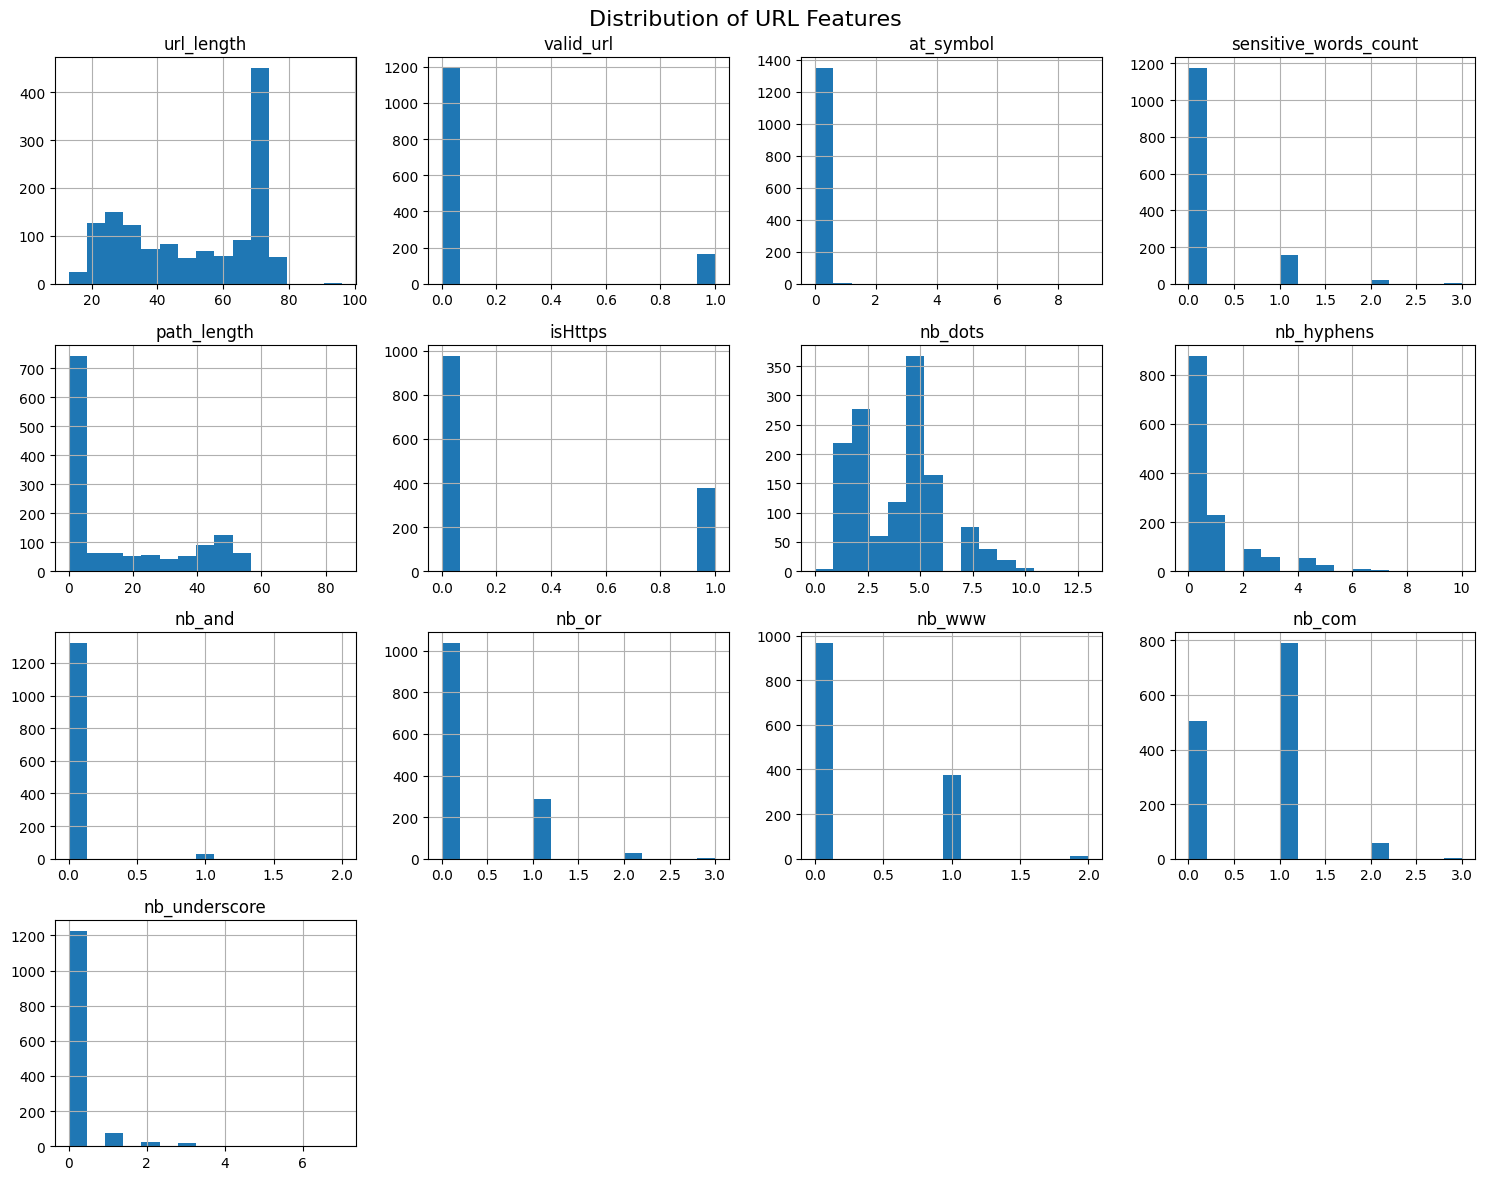

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ['url_length', 'valid_url', 'at_symbol', 'sensitive_words_count',
            'path_length', 'isHttps', 'nb_dots', 'nb_hyphens',
            'nb_and', 'nb_or', 'nb_www', 'nb_com', 'nb_underscore']

df[features].hist(figsize=(15, 12), bins=15)
plt.suptitle('Distribution of URL Features', fontsize=16)
plt.tight_layout()
plt.show()

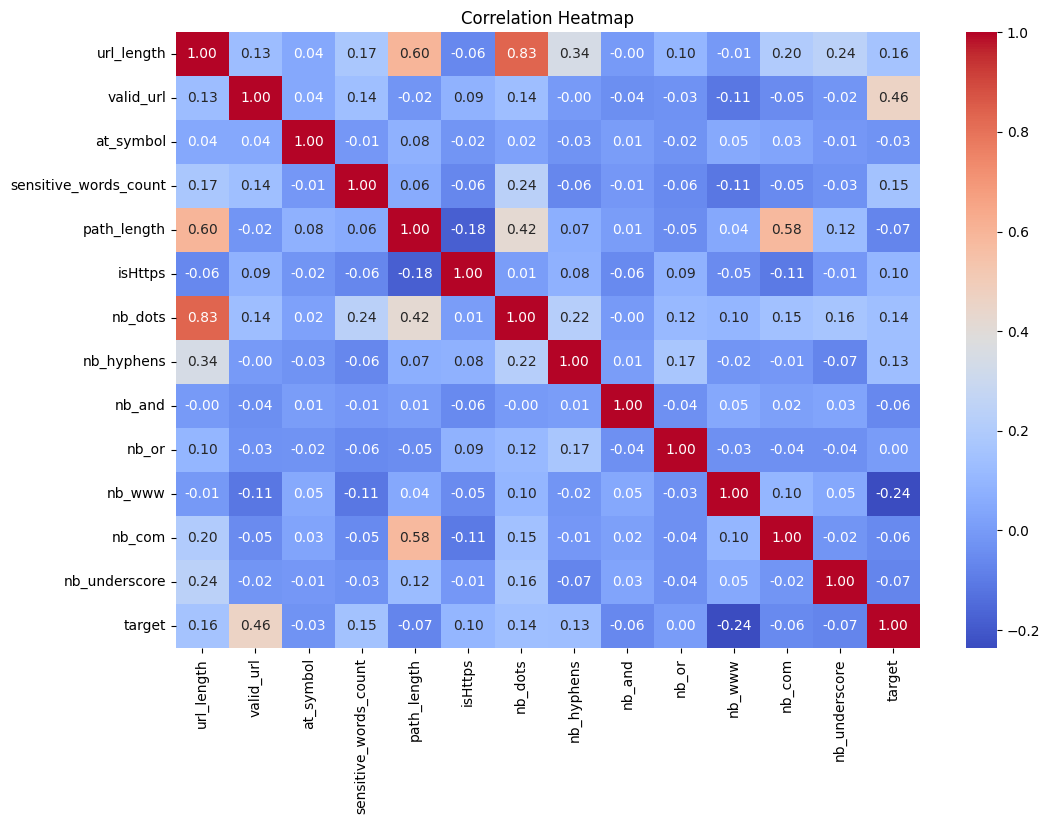

In [16]:
plt.figure(figsize=(12, 8))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

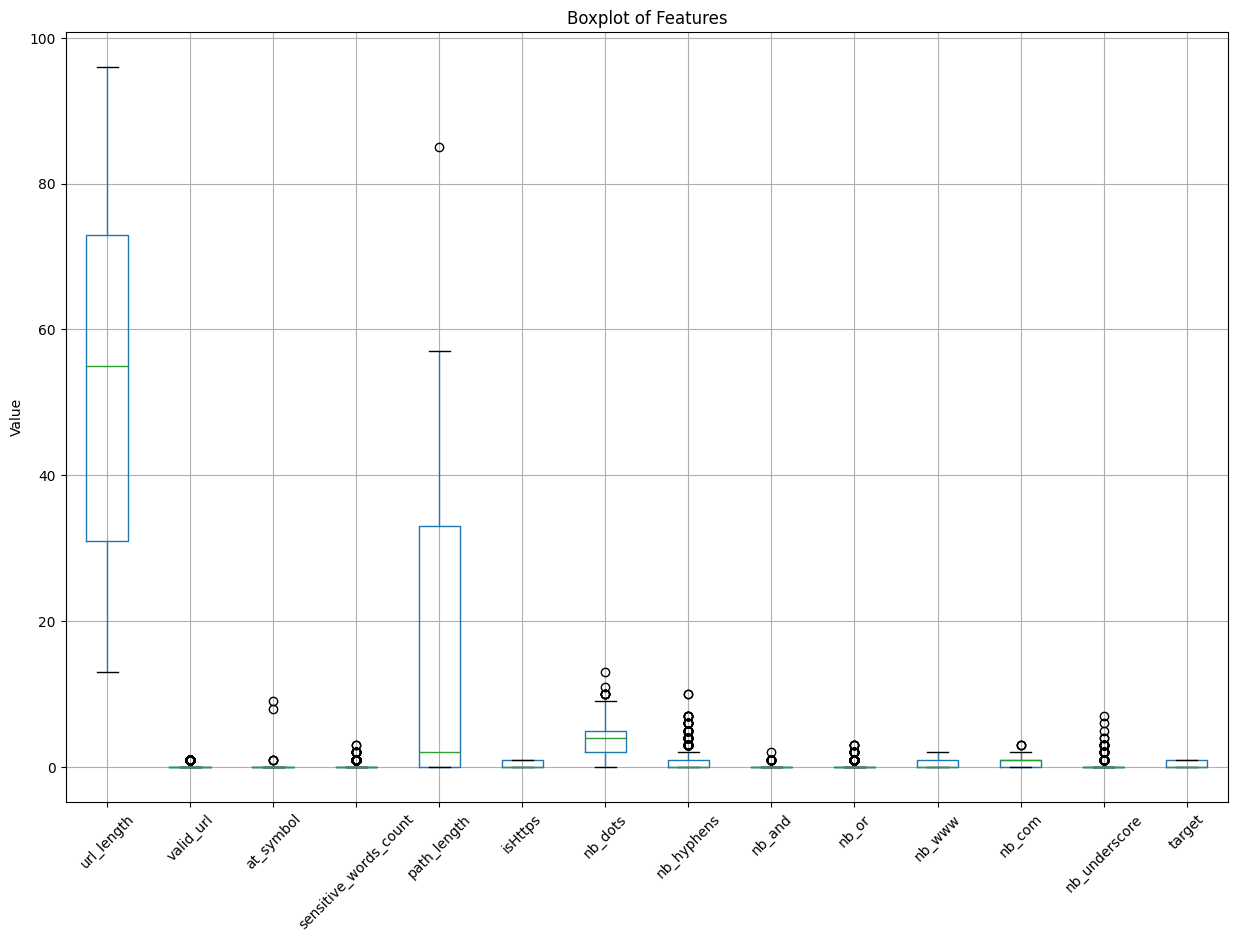

In [17]:
plt.figure(figsize=(15, 10))

df.boxplot()

plt.xticks(rotation=45)
plt.title('Boxplot of Features')
plt.ylabel('Value')

plt.show()

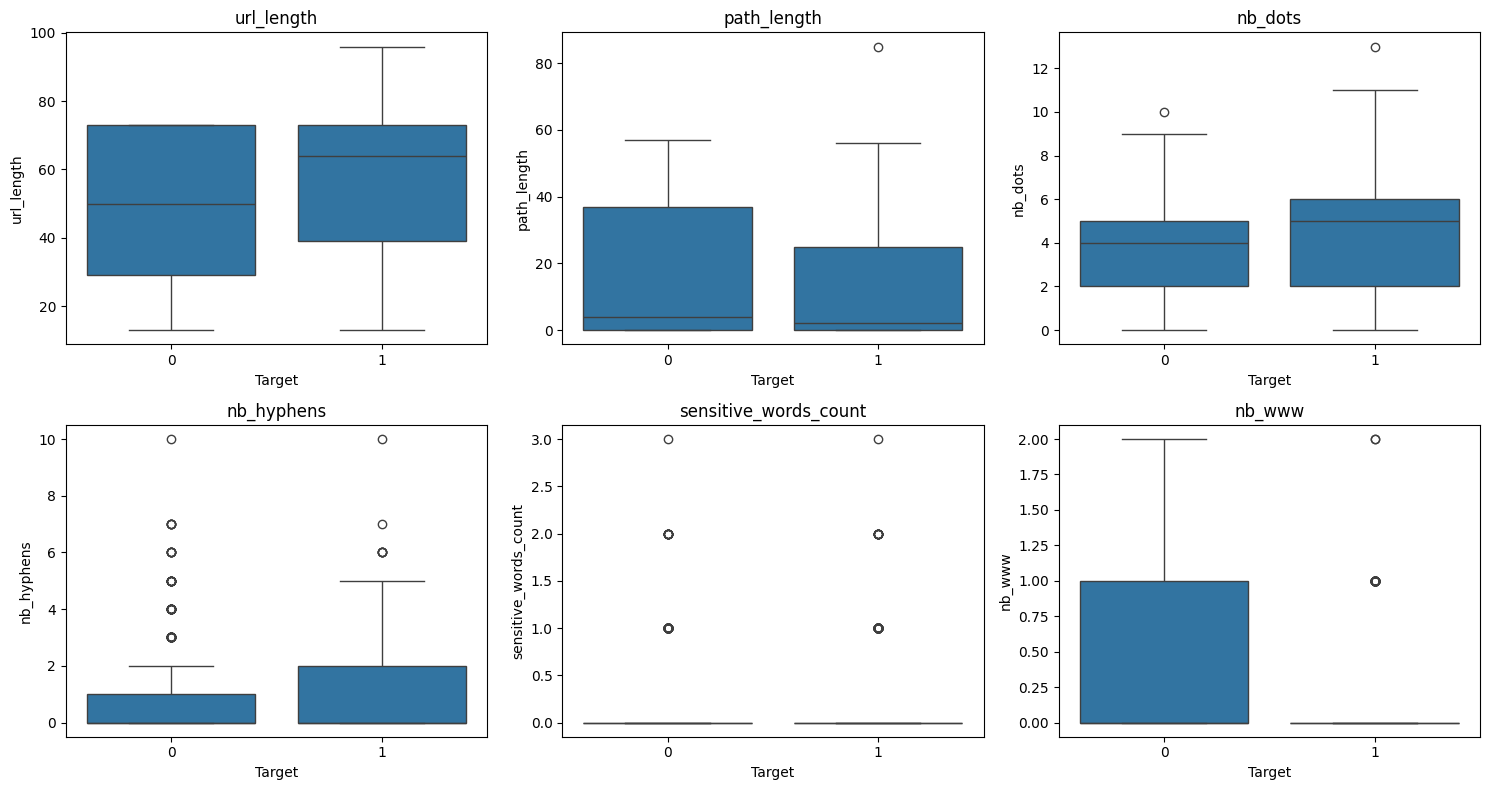

In [18]:
features = [
    'url_length',
    'path_length',
    'nb_dots',
    'nb_hyphens',
    'sensitive_words_count',
    'nb_www'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature in zip(axes.flat, features):
    sns.boxplot(data=df, x='target', y=feature, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel('Target')

plt.tight_layout()
plt.show()

In [19]:
X = df.drop('target', axis=1)
y = df['target']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1354, 13)
Target shape: (1354,)


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1083, 13)
Testing data: (271, 13)


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [23]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

y_pred_logistic = logistic_model.predict(X_test_scaled)
y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [24]:
ridge_model = LogisticRegression(
    penalty='l2',
    C=1.0,
    solver='liblinear',
    max_iter=1000,
    random_state=42
)

ridge_model.fit(X_train_scaled, y_train)

y_pred_ridge = ridge_model.predict(X_test_scaled)
y_prob_ridge = ridge_model.predict_proba(X_test_scaled)[:, 1]

print("Ridge Logistic Regression model trained successfully.")

Ridge Logistic Regression model trained successfully.


In [25]:
lasso_model = LogisticRegression(
    penalty='l1',
    C=1.0,
    solver='liblinear',
    max_iter=1000,
    random_state=42
)

lasso_model.fit(X_train_scaled, y_train)

y_pred_lasso = lasso_model.predict(X_test_scaled)
y_prob_lasso = lasso_model.predict_proba(X_test_scaled)[:, 1]

print("Lasso Logistic Regression model trained successfully.")

Lasso Logistic Regression model trained successfully.


In [26]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

results = []

models = {
    'Logistic Regression': (y_pred_logistic, y_prob_logistic),
    'Ridge Logistic Regression': (y_pred_ridge, y_prob_ridge),
    'Lasso Logistic Regression': (y_pred_lasso, y_prob_lasso)
}

for name, (pred, prob) in models.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1 Score': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)

print(results_df)

                       Model  Accuracy  Precision    Recall  F1 Score  \
0        Logistic Regression  0.771218   0.759259  0.455556  0.569444   
1  Ridge Logistic Regression  0.771218   0.759259  0.455556  0.569444   
2  Lasso Logistic Regression  0.771218   0.759259  0.455556  0.569444   

    ROC-AUC  
0  0.799877  
1  0.799693  
2  0.800246  


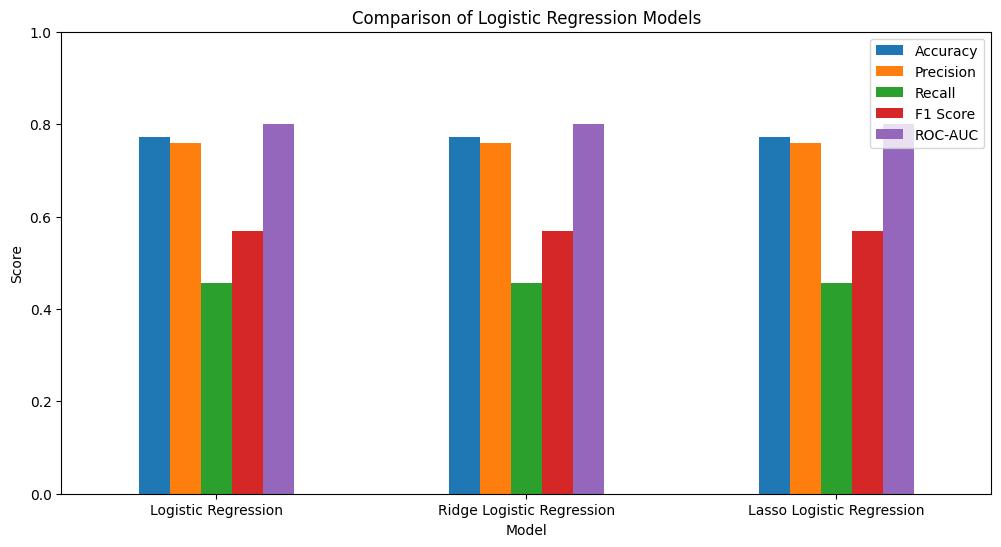

In [27]:
results_plot = results_df.set_index('Model')

results_plot[['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Comparison of Logistic Regression Models')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

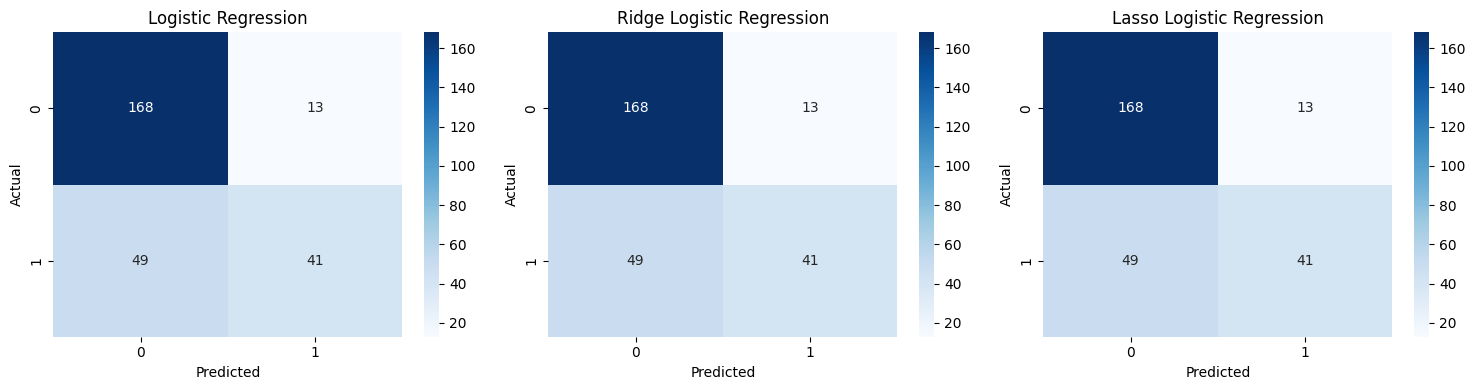

In [28]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

predictions = [
    ('Logistic Regression', y_pred_logistic),
    ('Ridge Logistic Regression', y_pred_ridge),
    ('Lasso Logistic Regression', y_pred_lasso)
]

for ax, (name, pred) in zip(axes, predictions):
    cm = confusion_matrix(y_test, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [29]:
from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_logistic))

print("\nRIDGE LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_ridge))

print("\nLASSO LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_lasso))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.77      0.93      0.84       181
           1       0.76      0.46      0.57        90

    accuracy                           0.77       271
   macro avg       0.77      0.69      0.71       271
weighted avg       0.77      0.77      0.75       271


RIDGE LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.77      0.93      0.84       181
           1       0.76      0.46      0.57        90

    accuracy                           0.77       271
   macro avg       0.77      0.69      0.71       271
weighted avg       0.77      0.77      0.75       271


LASSO LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.77      0.93      0.84       181
           1       0.76      0.46      0.57        90

    accuracy                           0.77       271
   macro avg       0.77      0.69      0.71       271


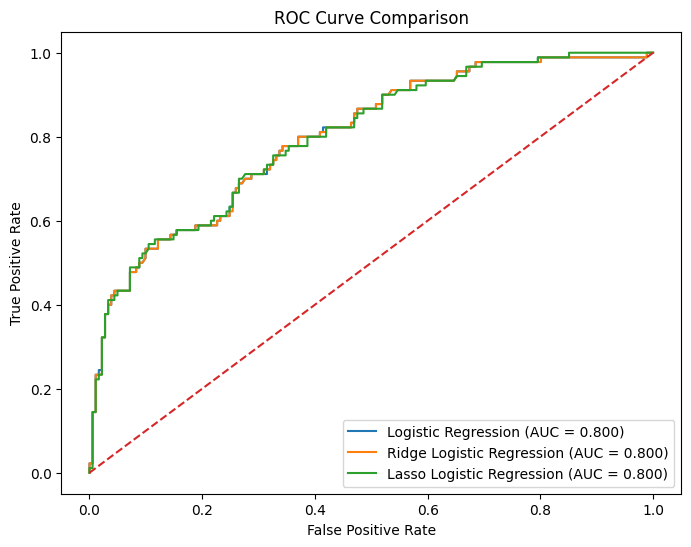

In [30]:
from sklearn.metrics import roc_curve, auc

fpr_logistic, tpr_logistic, _ = roc_curve(y_test, y_prob_logistic)
fpr_ridge, tpr_ridge, _ = roc_curve(y_test, y_prob_ridge)
fpr_lasso, tpr_lasso, _ = roc_curve(y_test, y_prob_lasso)

auc_logistic = auc(fpr_logistic, tpr_logistic)
auc_ridge = auc(fpr_ridge, tpr_ridge)
auc_lasso = auc(fpr_lasso, tpr_lasso)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f'Logistic Regression (AUC = {auc_logistic:.3f})'
)

plt.plot(
    fpr_ridge,
    tpr_ridge,
    label=f'Ridge Logistic Regression (AUC = {auc_ridge:.3f})'
)

plt.plot(
    fpr_lasso,
    tpr_lasso,
    label=f'Lasso Logistic Regression (AUC = {auc_lasso:.3f})'
)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

In [31]:
feature_names = X.columns

coefficient_df = pd.DataFrame({
    'Feature': feature_names,
    'Logistic Regression': logistic_model.coef_[0],
    'Ridge': ridge_model.coef_[0],
    'Lasso': lasso_model.coef_[0]
})

print(coefficient_df)

                  Feature  Logistic Regression     Ridge     Lasso
0              url_length             0.609885  0.608466  0.565555
1               valid_url             1.169995  1.172258  1.175929
2               at_symbol            -0.529703 -0.519325 -0.347045
3   sensitive_words_count             0.169712  0.169749  0.161626
4             path_length            -0.532479 -0.531957 -0.510538
5                 isHttps             0.085866  0.085753  0.078034
6                 nb_dots            -0.072254 -0.071586 -0.038321
7              nb_hyphens             0.204412  0.204337  0.205401
8                  nb_and            -0.072373 -0.072170 -0.066288
9                   nb_or            -0.037641 -0.037697 -0.029815
10                 nb_www            -0.535779 -0.534345 -0.533148
11                 nb_com             0.119909  0.119505  0.104720
12          nb_underscore            -0.196200 -0.195375 -0.186068


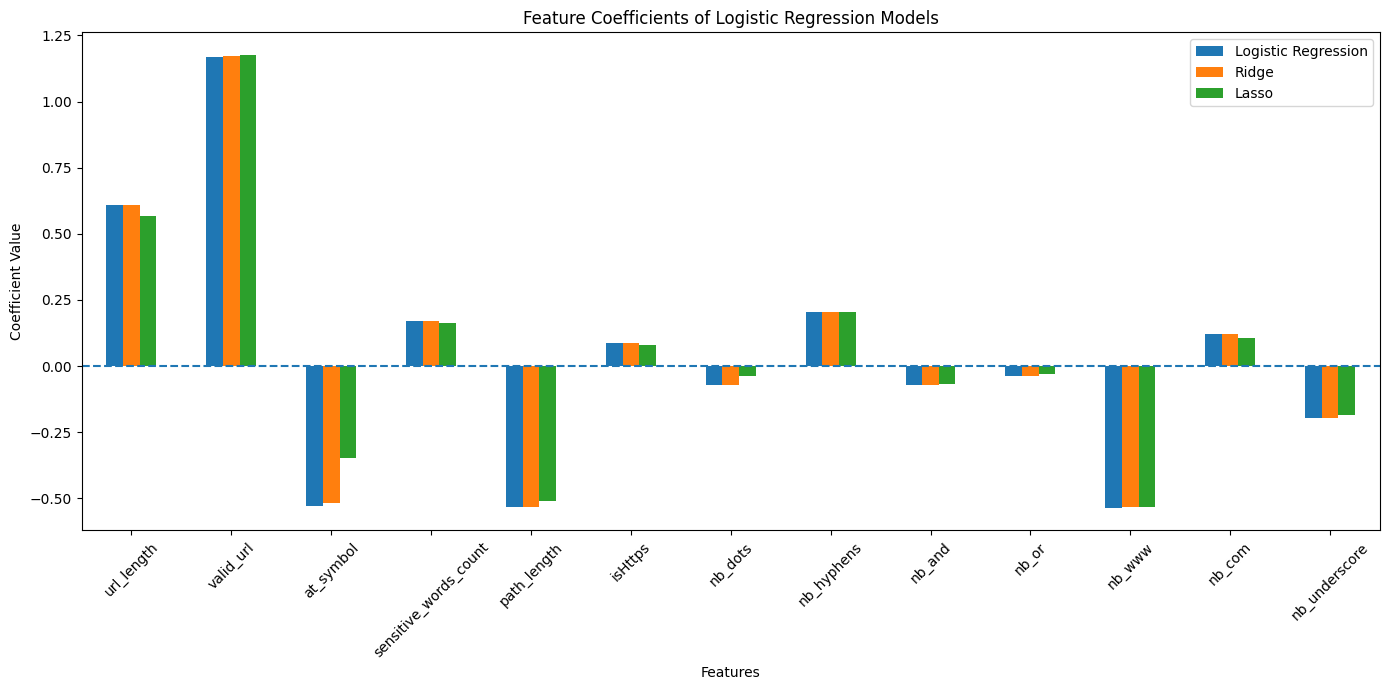

In [32]:
coefficient_df.set_index('Feature').plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title('Feature Coefficients of Logistic Regression Models')
plt.xlabel('Features')
plt.ylabel('Coefficient Value')
plt.xticks(rotation=45)
plt.axhline(0, linestyle='--')
plt.tight_layout()
plt.show()

In [33]:
lasso_coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lasso_model.coef_[0]
})

print(lasso_coefficients.sort_values(
    by='Coefficient',
    key=abs,
    ascending=False
))

                  Feature  Coefficient
1               valid_url     1.175929
0              url_length     0.565555
10                 nb_www    -0.533148
4             path_length    -0.510538
2               at_symbol    -0.347045
7              nb_hyphens     0.205401
12          nb_underscore    -0.186068
3   sensitive_words_count     0.161626
11                 nb_com     0.104720
5                 isHttps     0.078034
8                  nb_and    -0.066288
6                 nb_dots    -0.038321
9                   nb_or    -0.029815


In [34]:
zero_coefficients = (lasso_model.coef_[0] == 0).sum()

print("Number of zero coefficients in Lasso:", zero_coefficients)

Number of zero coefficients in Lasso: 0


In [35]:
results_df = results_df.round(4)

print("FINAL MODEL COMPARISON")
print(results_df)

FINAL MODEL COMPARISON
                       Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0        Logistic Regression    0.7712     0.7593  0.4556    0.5694   0.7999
1  Ridge Logistic Regression    0.7712     0.7593  0.4556    0.5694   0.7997
2  Lasso Logistic Regression    0.7712     0.7593  0.4556    0.5694   0.8002


In [36]:
import joblib

joblib.dump(ridge_model, 'ridge_logistic_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Model and scaler saved successfully.")

Model and scaler saved successfully.


In [37]:
new_url = [[
    50,    # url_length
    1,     # valid_url
    0,     # at_symbol
    0,     # sensitive_words_count
    20,    # path_length
    1,     # isHttps
    3,     # nb_dots
    1,     # nb_hyphens
    0,     # nb_and
    0,     # nb_or
    1,     # nb_www
    1,     # nb_com
    0      # nb_underscore
]]

new_url_scaled = scaler.transform(new_url)

prediction = ridge_model.predict(new_url_scaled)

print("Predicted class:", prediction[0])

Predicted class: 1


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
